In [1]:
!pip install wget
url = "https://raw.githubusercontent.com/kannera/keyword_course2021/main/korp_api.py"
!wget --no-check-certificate $url -O korp.py
url = "https://raw.githubusercontent.com/kannera/keyword_course2021/main/eng_corpus.py"
!wget --no-check-certificate $url -O eng_corpus.py


  Created wheel for wget: filename=wget-3.2-py3-none-any.whl size=9675 sha256=0ba1cc2b59a468907cafdbdcf7fbc348aef41b2286178cf5cfc8b6fbfc21a691
  Stored in directory: /root/.cache/pip/wheels/a1/b6/7c/0e63e34eb06634181c63adacca38b79ff8f35c37e3c13e3c02
Successfully built wget
--2022-03-08 08:21:42--  https://raw.githubusercontent.com/kannera/keyword_course2021/main/korp_api.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.110.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 9092 (8.9K) [text/plain]
Saving to: ‘korp.py’

korp.py             100%[===================>]   8.88K  --.-KB/s    in 0s      

2022-03-08 08:21:42 (65.3 MB/s) - ‘korp.py’ saved [9092/9092]

--2022-03-08 08:21:42--  https://raw.githubusercontent.com/kannera/keyword_course2021/main/eng_corpus.py
Resolving raw.githubusercontent.com (raw.github

In [2]:
import json, os, re, sys, codecs
import matplotlib.pyplot as plt
import pandas
import wget
from korp import *
from eng_corpus import *

In [9]:
def get_total_frequency_for_lemma(lemma, corpus):
  if corpus == "klk": groupby = "text_issue_date"
  elif corpus == "suomi24": groupby = "text_date"
  data = get_frequency_data_from_korp('[lemma="'+lemma+'"]', groupby, corpus, sums=True)
  print("total absolute frequency for", lemma, data['abs_frequency'])
  print("total relative frequency for", lemma, data['rel_frequency'])


In [12]:
#this will count the total frequency of the lemma vilja ('grain') in the Natinal Libarary Historical Newspaper Collection ("klk")
#the result is produced as an absolute frequency and an relative frequency (relative to full token count, to 10k words (I think))
#the first argument of the function get_total_frequency_for_lemma() is for the lemma and the second one for the corpus
get_total_frequency_for_lemma("neiti", "klk")
get_total_frequency_for_lemma("neiti", "suomi24")

https://korp.csc.fi/cgi-bin/korp/korp.cgi?command=count&defaultcontext=DEFAULT_CONTEXT&cache=true&groupby=text_issue_date&cqp=%5Blemma%3D%22neiti%22%5D&context=&incremental=true&defaultwithin=sentence&within=&loginfo=lang%3Dfi+search%3Dadv&corpus=KLK_FI_18%2899.98.97.96.95.94.93.92.91.90.89.88.87.86.85.84.83.82.81.80.79.78.77.76.75.74.73.72.71.70.69.68.67.66.65.64.63.62.61.60%29
total absolute frequency for neiti 355822
total relative frequency for neiti 258.20215494429175
https://korp.csc.fi/cgi-bin/korp/korp.cgi?command=count&defaultcontext=DEFAULT_CONTEXT&cache=true&groupby=text_date&cqp=%5Blemma%3D%22neiti%22%5D&context=&incremental=true&defaultwithin=sentence&within=&loginfo=lang%3Dfi+search%3Dadv&corpus=S24_200%281.2.3.4.5.6.7.8.9%29.S24_201%280.1.2.3.4.5.6.7.8.9%29.S24_2020
total absolute frequency for neiti 91691
total relative frequency for neiti 20.008691411036427


In [13]:
#however, the klk corpus has three common problems related to queries:
# 1) historical orthography
# 2) somewhat messy OCR (optical character recognition, used when scanning the original papers to digital texts)
# 3) unreliable automated annotation
#for these reasons, queries do not always return the correct values reliably. For example, letter w was almost consistently
#used until late 19th/early 20th century in place of modern v. The lemmatization process has not identified words with w and
#considers them different types to ones with v
#see what happens when we query for "wilja" instead of "vilja"
get_total_frequency_for_lemma("vaivaisukko", "suomi24")

https://korp.csc.fi/cgi-bin/korp/korp.cgi?command=count&defaultcontext=DEFAULT_CONTEXT&cache=true&groupby=text_date&cqp=%5Blemma%3D%22vaivaisukko%22%5D&context=&incremental=true&defaultwithin=sentence&within=&loginfo=lang%3Dfi+search%3Dadv&corpus=S24_200%281.2.3.4.5.6.7.8.9%29.S24_201%280.1.2.3.4.5.6.7.8.9%29.S24_2020
total absolute frequency for vaivaisukko 33
total relative frequency for vaivaisukko 0.00720121731210481


In [ ]:
#why was the count smaller than with vilja if w was consistently used?
#the reason is that the preparsing has failed with w-words, as the technology trained with
#modern finnish does not recognize words with w correctly. Each individual case of words with w
#have been identified as separate lemmas.
#see what happens when instead of one lemma, we ask the api to look for combination of list of lemmas.
#here are the most common singular case forms of the word vilja with w.
get_total_frequency_for_lemma("(wilja|wiljaa|wiljan|wiljasta|wiljaan|wiljassa|wiljalla|wiljalta|wiljalle|wiljaksi|wiljana)", "klk")


total absolute frequency for (wilja|wiljaa|wiljan|wiljasta|wiljaan|wiljassa|wiljalla|wiljalta|wiljalle|wiljaksi|wiljana) 25403
total relative frequency for (wilja|wiljaa|wiljan|wiljasta|wiljaan|wiljassa|wiljalla|wiljalta|wiljalle|wiljaksi|wiljana) 18.43368128460253


In [ ]:
#by using regular expressions (a way to formally describe string of characters understood by most search engines) we can shorten the above query
#and add plural forms
lemmaB="wilj(a|oi)(|t|na*|an*|s(s|t)a|l(la|le|ta)|ksi)"

get_total_frequency_for_lemma(lemmaB, "klk")

total absolute frequency for wilj(a|oi)(|t|na*|an*|s(s|t)a|l(la|le|ta)|ksi) 27024
total relative frequency for wilj(a|oi)(|t|na*|an*|s(s|t)a|l(la|le|ta)|ksi) 19.60995957308581


In [ ]:
#the problem of messy OCR, historical orthography and consequent bad lemmatization is a common problem in 
#all large-scale historical corpora. We will not go that much deeper in it, but be mindful if you happen
#to choose a word with the letter v in it. ask for help, if you bump into problems.

#let's look at some time series next

In [ ]:
#in order to compute relative frequencies later on, we first need to query daily, monthly, yearly and per-decade total 
#frequencies for the klk corpus
total_frequencies = query_full_corpus_sizes("klk")


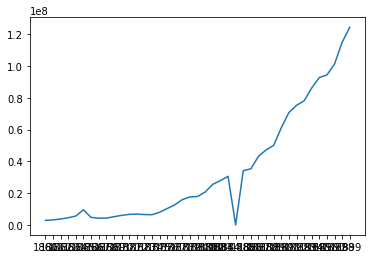

In [ ]:
#plotting the total frequencies as a graph tells us that the variation between corpus sizes is not random,
#but the yearly datasets grow exponentially. We have to take this into account.
plt.plot(total_frequencies.groupby('year').sum()['frequency'])

In [ ]:
#first, this block will produce a per-decade time series of the lemma "vilja" (with a v) in the data
#this will query the frequencies of the queried lemma ("vilja") by day and store it in a table form, where
#each row represents a day and the column 'lemma' holds the frequencies of that day. Additional columns include 
#months, years and decades, by which the rows can be summed. Ie. finding all the rows with decade '1860' and summing 
#their daily frequencies and so on. If you want to run the same analyses on some other words, just change the value for
#the variable lemmaA below:
lemmaA = "vilja"
corpus = "klk"
data_A = get_frequency_data_from_korp('[lemma="'+lemmaA+'"]', "text_issue_date", corpus)
data_A_per_year = data_A.groupby('year').sum()['abs_frequency']


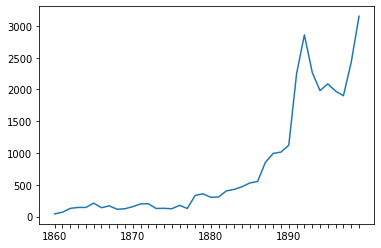

year
1899    3152
1892    2859
1898    2427
1893    2270
1891    2248
1895    2088
1894    1982
1896    1973
1897    1901
1890    1123
Name: abs_frequency, dtype: int64


In [ ]:
for y in total_frequencies['year'].unique():
  if y not in data_A_per_year.index:
    data_A_per_year.loc[y] = 0
data_A_per_year = data_A_per_year.sort_index()
data_A_per_year.drop('1884-1885', inplace=True)
#the outcome is produced here
#the lines below plot a time series as a bar graph
#the two first are dedicated to getting the x-axis labels show up nicely
plt.plot(list(range(data_A_per_year.shape[0])), data_A_per_year.values)
x_labels = [str(x) if int(x) in range(1860,1910,10) else "" for x in data_A_per_year.index.to_list()]
plt.xticks(ticks=list(range(data_A_per_year.shape[0])),labels=x_labels)
plt.show()

#list the top 10 years
#you can get eg. top 20 by changing the number inside the brackets to '20'
print(data_A_per_year.sort_values(ascending=False).head(10))

In [ ]:
#the frequency of vilja seems to grow, but how much of that growth is due the yearly corpus sizes growing as well?
#relative frequencies will show that. Let's plot the above graph, but using relative frequencies
data_A_per_year = data_A_per_year.div(total_frequencies.groupby('year').sum()['frequency'])

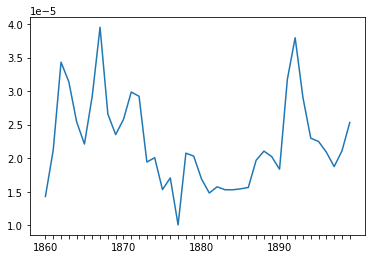

year
1867    0.000040
1892    0.000038
1862    0.000034
1891    0.000032
1863    0.000031
1871    0.000030
1866    0.000029
1872    0.000029
1893    0.000029
1868    0.000027
dtype: float64


In [ ]:
for y in total_frequencies['year'].unique():
  if y not in data_A_per_year.index:
    data_A_per_year.loc[y] = 0
data_A_per_year = data_A_per_year.sort_index()
data_A_per_year.drop('1884-1885', inplace=True)
#the outcome is produced here
#the lines below plot a time series as a bar graph
#the two first are dedicated to getting the x-axis labels show up nicely
plt.plot(list(range(data_A_per_year.shape[0])), data_A_per_year.values)
x_labels = [str(x) if int(x) in range(1860,1910,10) else "" for x in data_A_per_year.index.to_list()]
plt.xticks(ticks=list(range(data_A_per_year.shape[0])),labels=x_labels)
plt.show()

#list the top 10 years
#you can get eg. top 20 by changing the number inside the brackets to '20'
print(data_A_per_year.sort_values(ascending=False).head(10))

In [ ]:
#the great famine in Finland was in 1866–1868. How do the frequencies fit that?
#but what about wilja? let's add that to the graph!
#if you want to use this compare other two words, just change the values for the
#variables lemmaA and lemmaB below. lemmaB can be a "normal" word, it doesn't have to
#be a regex clause

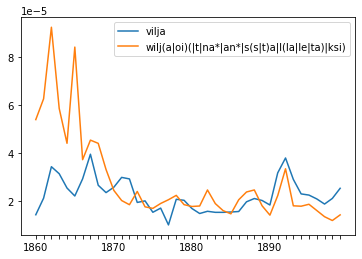

In [ ]:
lemmaA = "vilja"
lemmaB="wilj(a|oi)(|t|na*|an*|s(s|t)a|l(la|le|ta)|ksi)"
data_A = get_frequency_data_from_korp('[lemma="'+lemmaA+'"]', "text_issue_date", corpus)
data_A_per_year = data_A.groupby('year').sum()['abs_frequency']
data_A_per_year = data_A_per_year.div(total_frequencies.groupby('year').sum()['frequency'])

data_B = get_frequency_data_from_korp('[lemma="'+lemmaB+'"]', "text_issue_date", corpus)
data_B_per_year = data_B.groupby('year').sum()['abs_frequency']
data_B_per_year = data_B_per_year.div(total_frequencies.groupby('year').sum()['frequency'])
for y in total_frequencies['year'].unique():
  if y not in data_A_per_year.index:
    data_A_per_year.loc[y] = 0
  if y not in data_B_per_year.index:
    data_B_per_year.loc[y] = 0
data_A_per_year = data_A_per_year.sort_index()
data_A_per_year.drop('1884-1885', inplace=True)
data_B_per_year = data_B_per_year.sort_index()
data_B_per_year.drop('1884-1885', inplace=True)

plt.plot(list(range(data_A_per_year.shape[0])), data_A_per_year.values, label=lemmaA)
plt.plot(list(range(data_B_per_year.shape[0])), data_B_per_year.values, label=lemmaB)
x_labels = [str(x) if int(x) in range(1860,1910,10) else "" for x in data_A_per_year.index.to_list()]
plt.legend()
plt.xticks(ticks=list(range(data_A_per_year.shape[0])),labels=x_labels)
plt.show()

In [ ]:
#the picture seems pretty clear!
#but what kind of variation are we talking about? How does the monthly or daily numbers of "vilja" look like?
#for the sake of simplicity, we will stick to only vilja-occurrences (v, not w) and look at absolute frequencies

<BarContainer object of 478 artists>

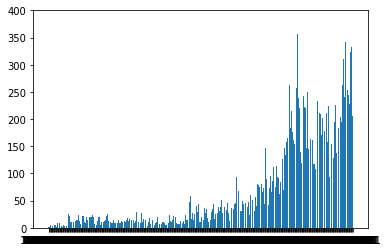

In [ ]:
data_A_per_month = data_A.groupby("month_date").sum()["abs_frequency"]
plt.bar(data_A_per_month.index, data_A_per_month.values)

<BarContainer object of 7203 artists>

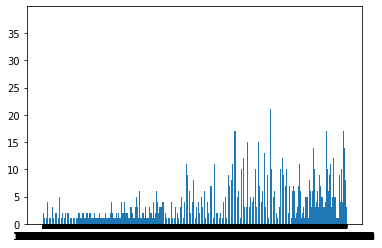

In [ ]:
#what happens to the shape of the graph? what about per day? WARNING this bit of code can take some time
data_A_per_day = data_A.groupby("date").sum()["abs_frequency"]
data_A_per_day.drop("no date", inplace=True)
plt.bar(data_A_per_day.index, data_A_per_day.values)

In [ ]:
#seems interesting! What observations can be drawn from comparing yearly, monthly and daily frequencies 
#from earlier and later part of the data?


In [ ]:
#let's now look at some of the peaks from the later part of the data. What are they made of?
#here is the list for top 10 dates in the dataset
print(data_A[data_A.date != "no date"].sort_values('abs_frequency', ascending=False)[['date','abs_frequency']].head(10))

            date  abs_frequency
1027  1899-04-28             38
4428  1896-08-22             38
6169  1892-09-10             37
3765  1892-10-07             36
2519  1887-09-10             34
4895  1896-02-13             31
5968  1896-07-07             31
3050  1894-08-23             30
6644  1894-07-24             29
2925  1892-10-04             29


In [ ]:
#Let's select one the top dates above, say 1887-09-10 and see which papers have the word vilja for that day and how are the 
#words distributed across the papers.
#we will have to query a new dataset, this time querying by both lemma and date and arranging the results by the name of the paper ('text_issue_title')
lemmaA = "vilja"
url = query_frequencies('[lemma="'+lemmaA+'" & _.text_issue_date="10.09.1887"]', "text_issue_title", "klk")
print(url)
peak_A = get_frequency_data_from_korp('[lemma="'+lemmaA+'" & _.text_issue_date="10.09.1887"]', 'text_issue_title', corpus)

https://korp.csc.fi/cgi-bin/korp/korp.cgi?command=count&defaultcontext=1+sentence&cache=true&groupby=text_issue_title&cqp=%5Blemma%3D%22vilja%22+%26+_.text_issue_date%3D%2210.09.1887%22%5D&context=&incremental=true&defaultwithin=sentence&within=&loginfo=lang%3Dfi+search%3Dadv&corpus=KLK_FI_18%2899.98.97.96.95.94.93.92.91.90.89.88.87.86.85.84.83.82.81.80.79.78.77.76.75.74.73.72.71.70.69.68.67.66.65.64.63.62.61.60%29


In [ ]:
print(peak_A)

      text_issue_title  rel_frequency  abs_frequency
0         Rauman Lehti       0.002903              4
1  Oulun Ilmoituslehti       0.000726              1
2        Uusi Suometar       0.001451              2
3                 Savo       0.002177              3
4            Aamulehti       0.010885             15
5     Wiipurin Sanomat       0.000726              1
6            Satakunta       0.000726              1
7          Turun Lehti       0.002177              3
8                Tapio       0.001451              2
9         Waasan Lehti       0.001451              2


In [ ]:
#it seems there indeed is one single paper, that contributes significantly to the formation of the peak

In [ ]:
#you can go locate the particular paper in digi.kansalliskirjasto.fi and look whether you can find the articles with vilja in them. What is the context?

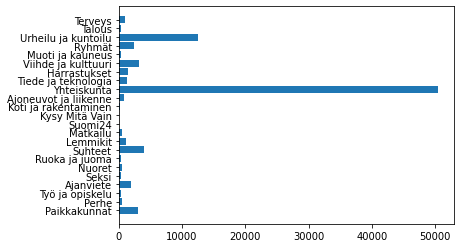

<Figure size 2000x2000 with 0 Axes>

In [ ]:
#other metadata categories besides the time can be used to identify frequency patterns in the data
#we now look at the suomi24 online discussion forum data
lemmaA = "leijona"
lemmaB = "tiikeri"
corpus = "suomi24"
#querying for frequencies of lemma "leijona" ('lion') in each top level forum area (text_topic_name) in suomi24 corpus
data_A = get_frequency_data_from_korp('[lemma="'+lemmaA+'"]', 'text_topic_name_top', corpus)
plt.barh(data_A['text_topic_name_top'], data_A['abs_frequency'])
plt.figure(figsize=(10,10), dpi=200)
plt.rcParams.update({'font.size': 10})
plt.show()

In [ ]:
#what could explain the high frequencies of Urheilu ja kuntoilu ('sports and fitness') and Yhteiskunta ('society') areas?
#Let's delve deeper

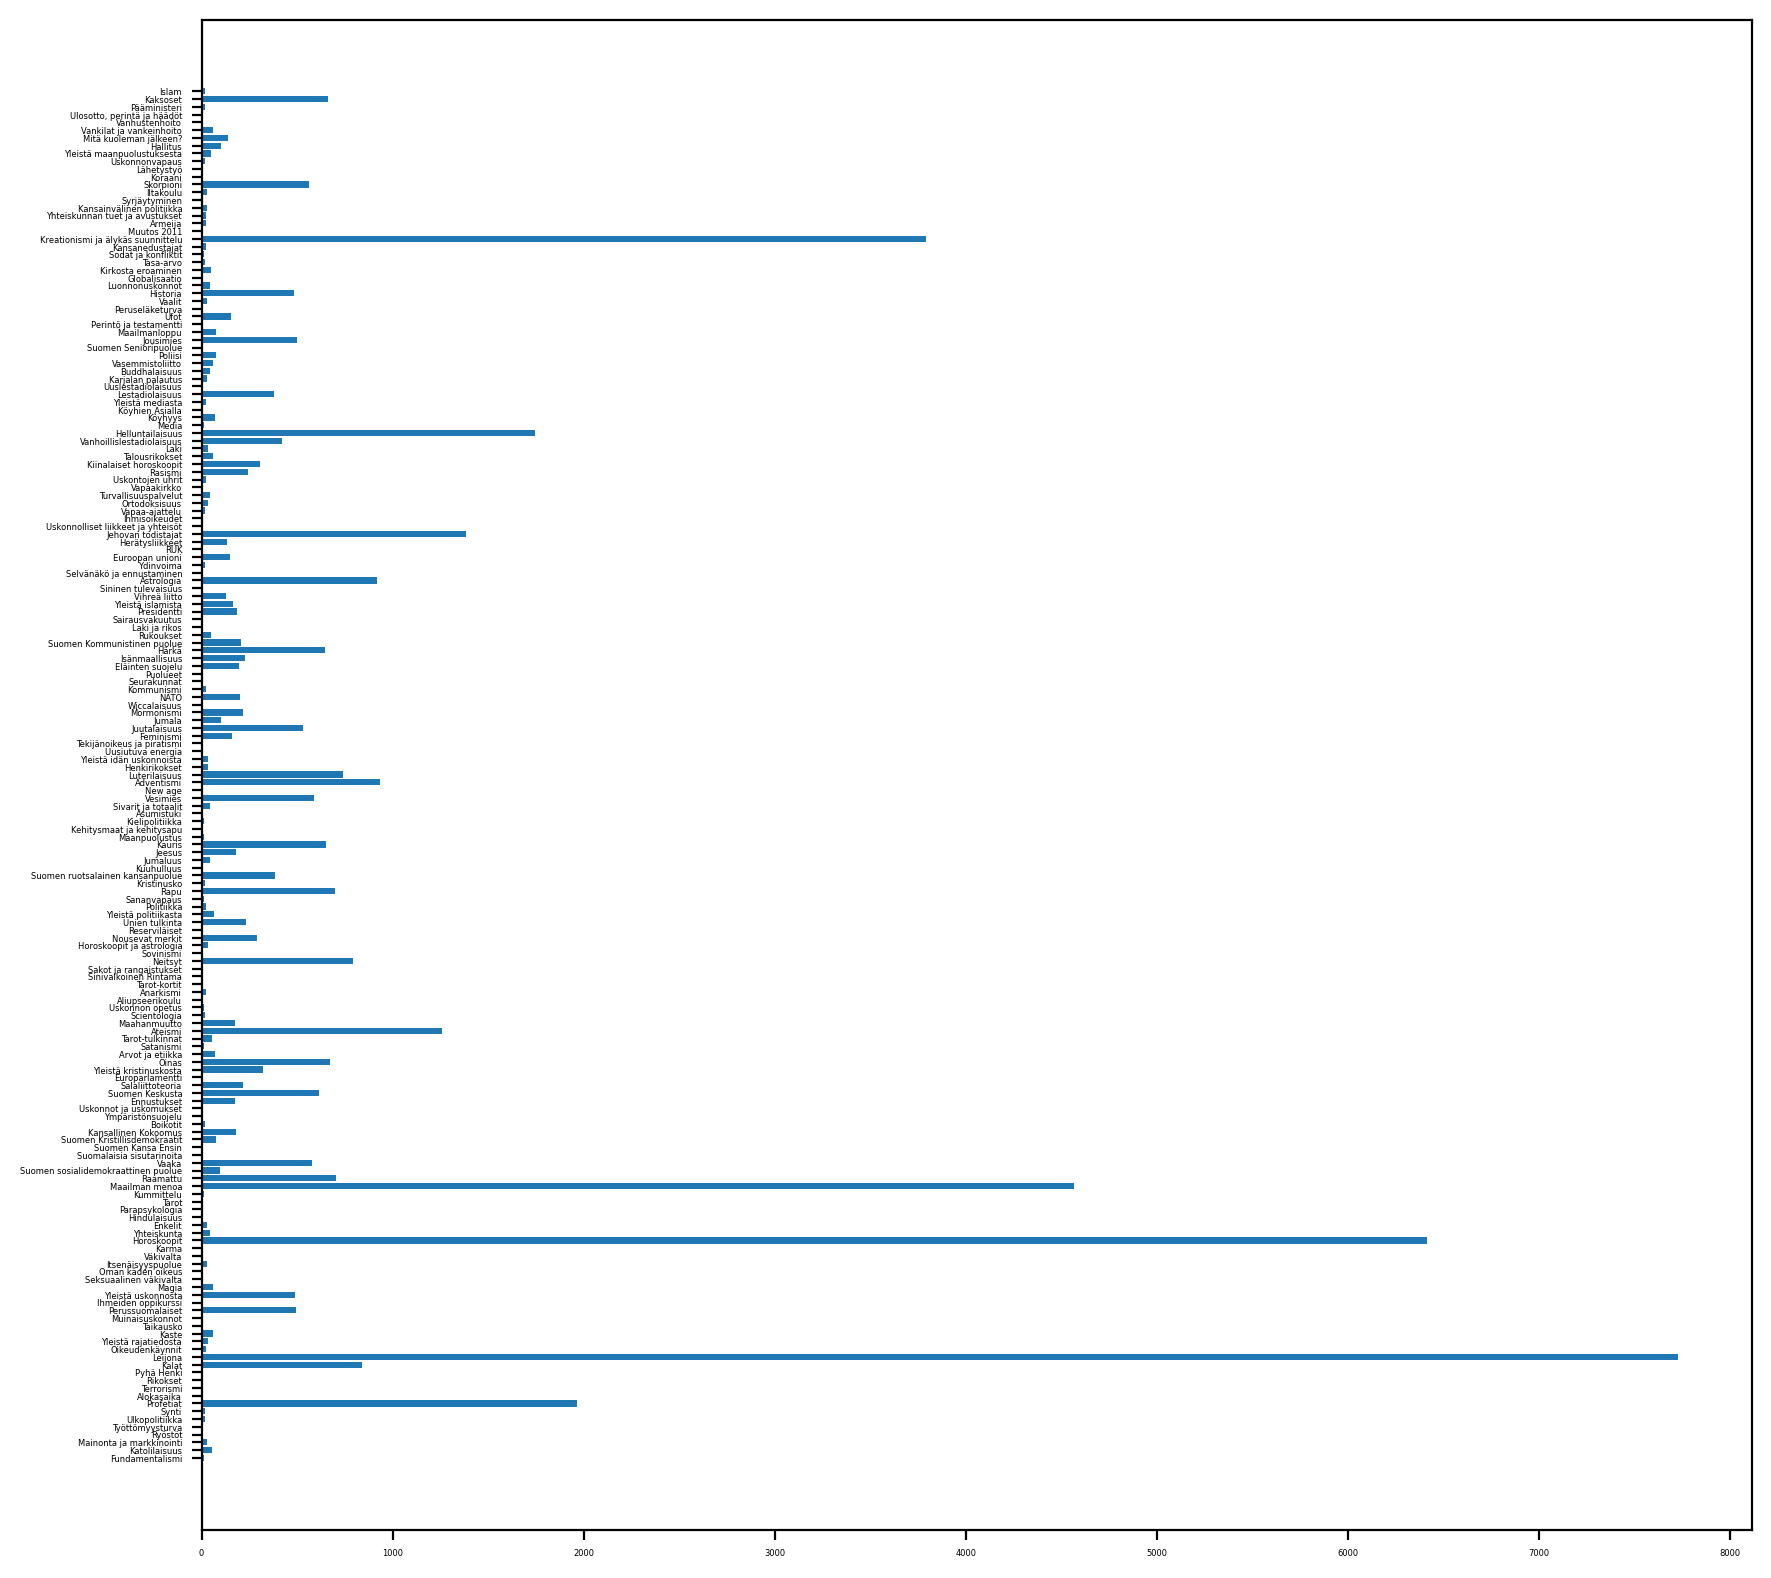

In [ ]:
#Looking at the Yhteiskunta area and studying its lower level discussion areas. 
#The top level area is entered into the query as "_.text_topic_name_top=" and grouping is now by lower level areas (text_topic_name_leaf)
data_A_soc = get_frequency_data_from_korp('[lemma="leijona" & _.text_topic_name_top = "Yhteiskunta"]', 'text_topic_name_leaf', 'suomi24')
plt.figure(figsize=(10,10), dpi=200)
plt.rcParams.update({'font.size': 3})
plt.barh(data_A_soc['text_topic_name_leaf'], data_A_soc['abs_frequency'])
plt.show()

In [ ]:
#looking at absolute frequencies shows how th occurrences of leijona distribute between areas or sub-areas. But it does not tell how salient
#or common the word is in those areas. For that we need relative frequencies.

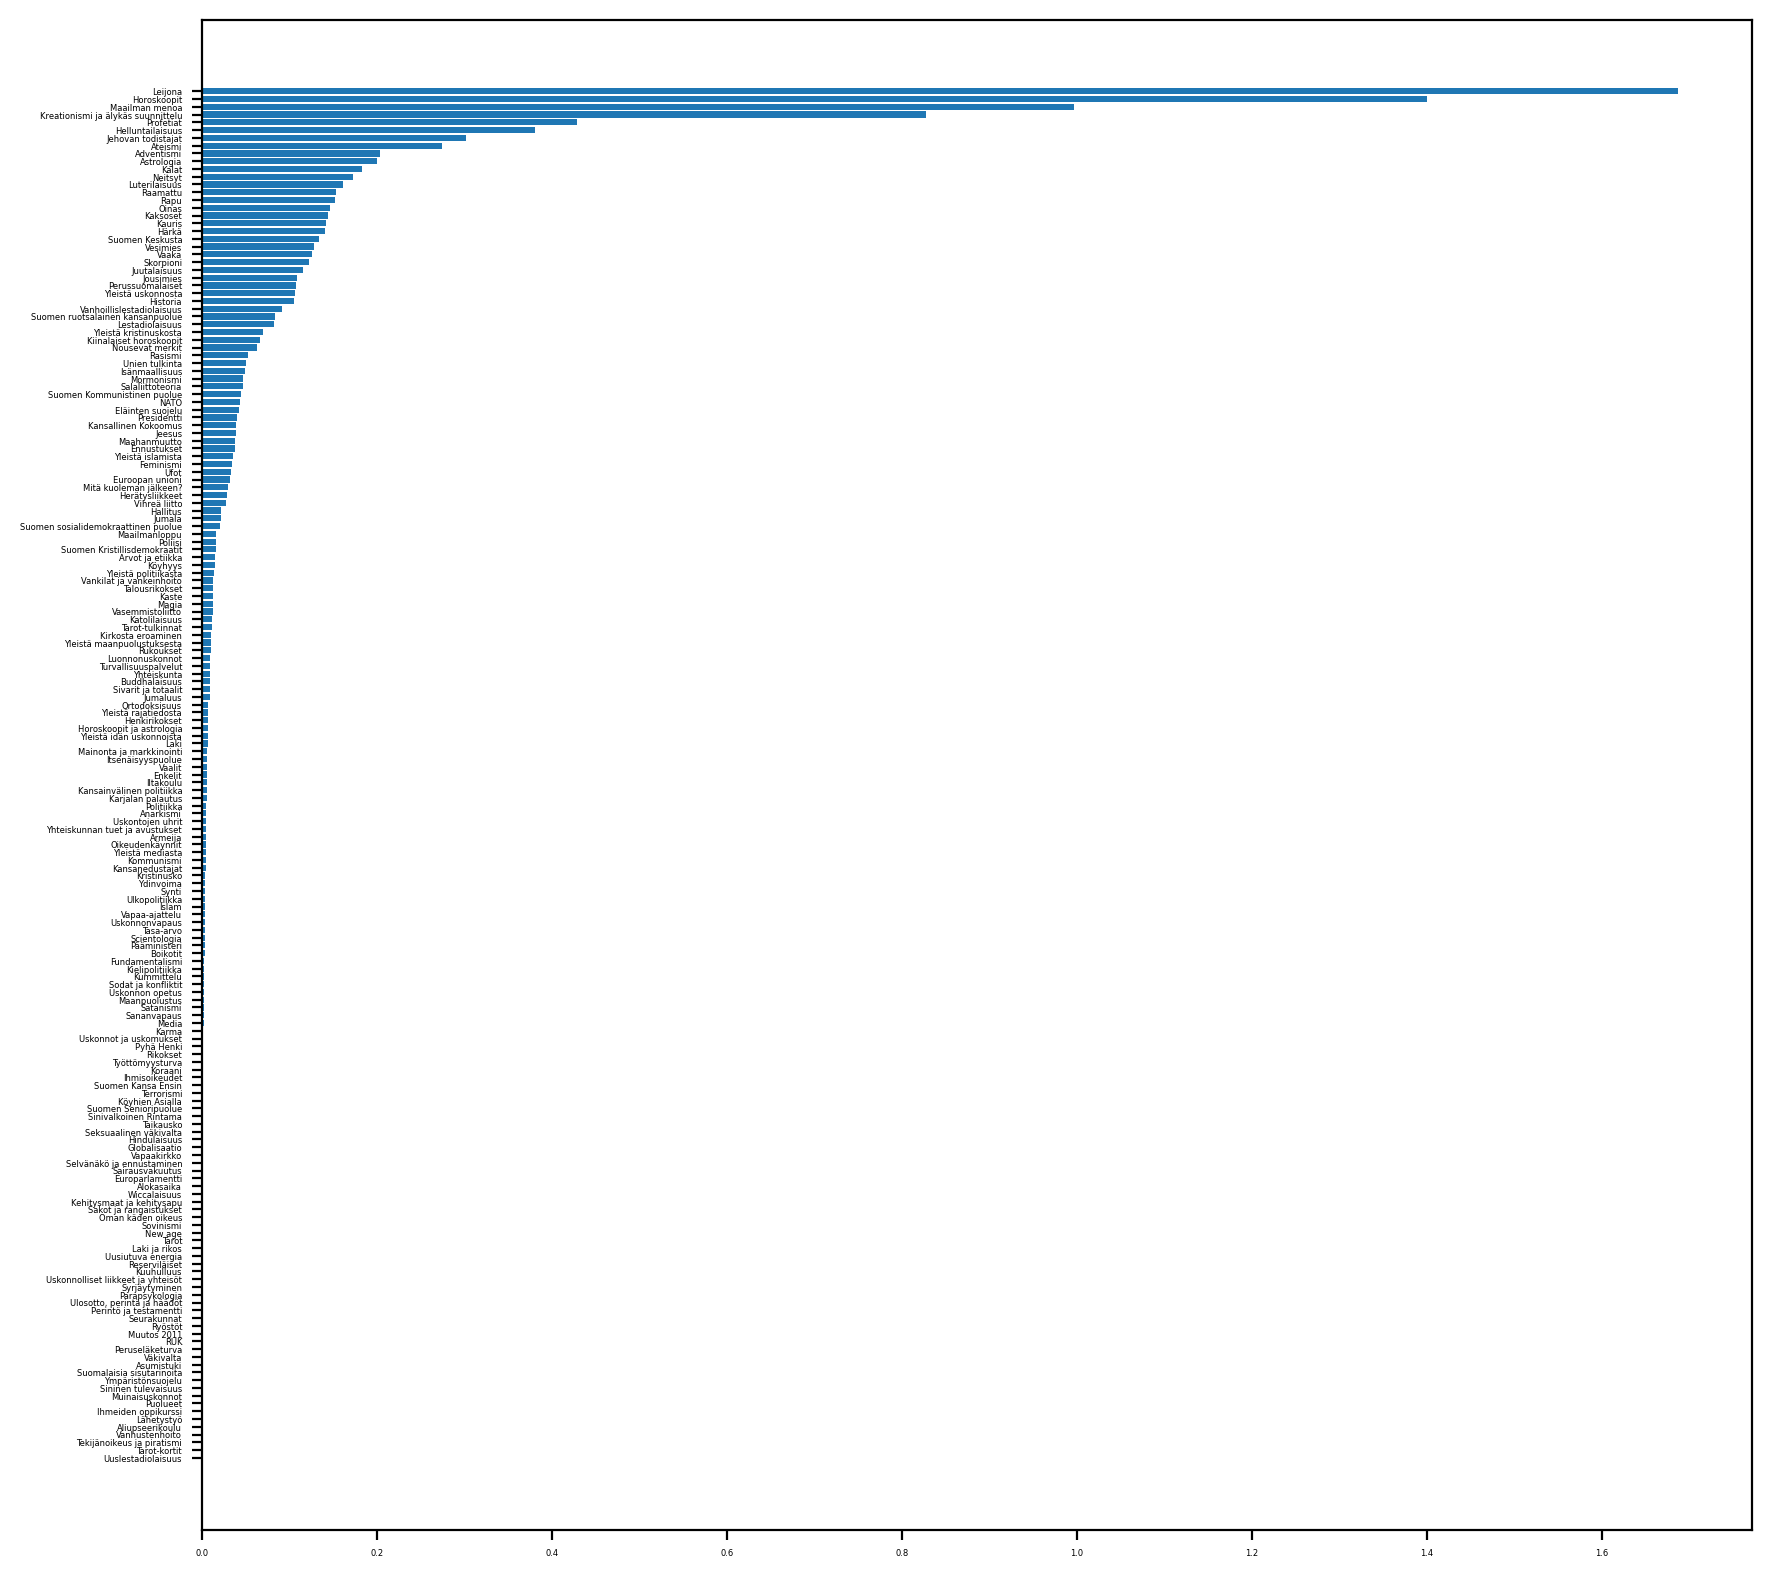

In [ ]:
plt.figure(figsize=(10,10), dpi=200)
plt.rcParams.update({'font.size': 3})
data_A_soc = data_A_soc.sort_values('rel_frequency')
plt.barh(data_A_soc['text_topic_name_leaf'], data_A_soc['rel_frequency'])
plt.show()

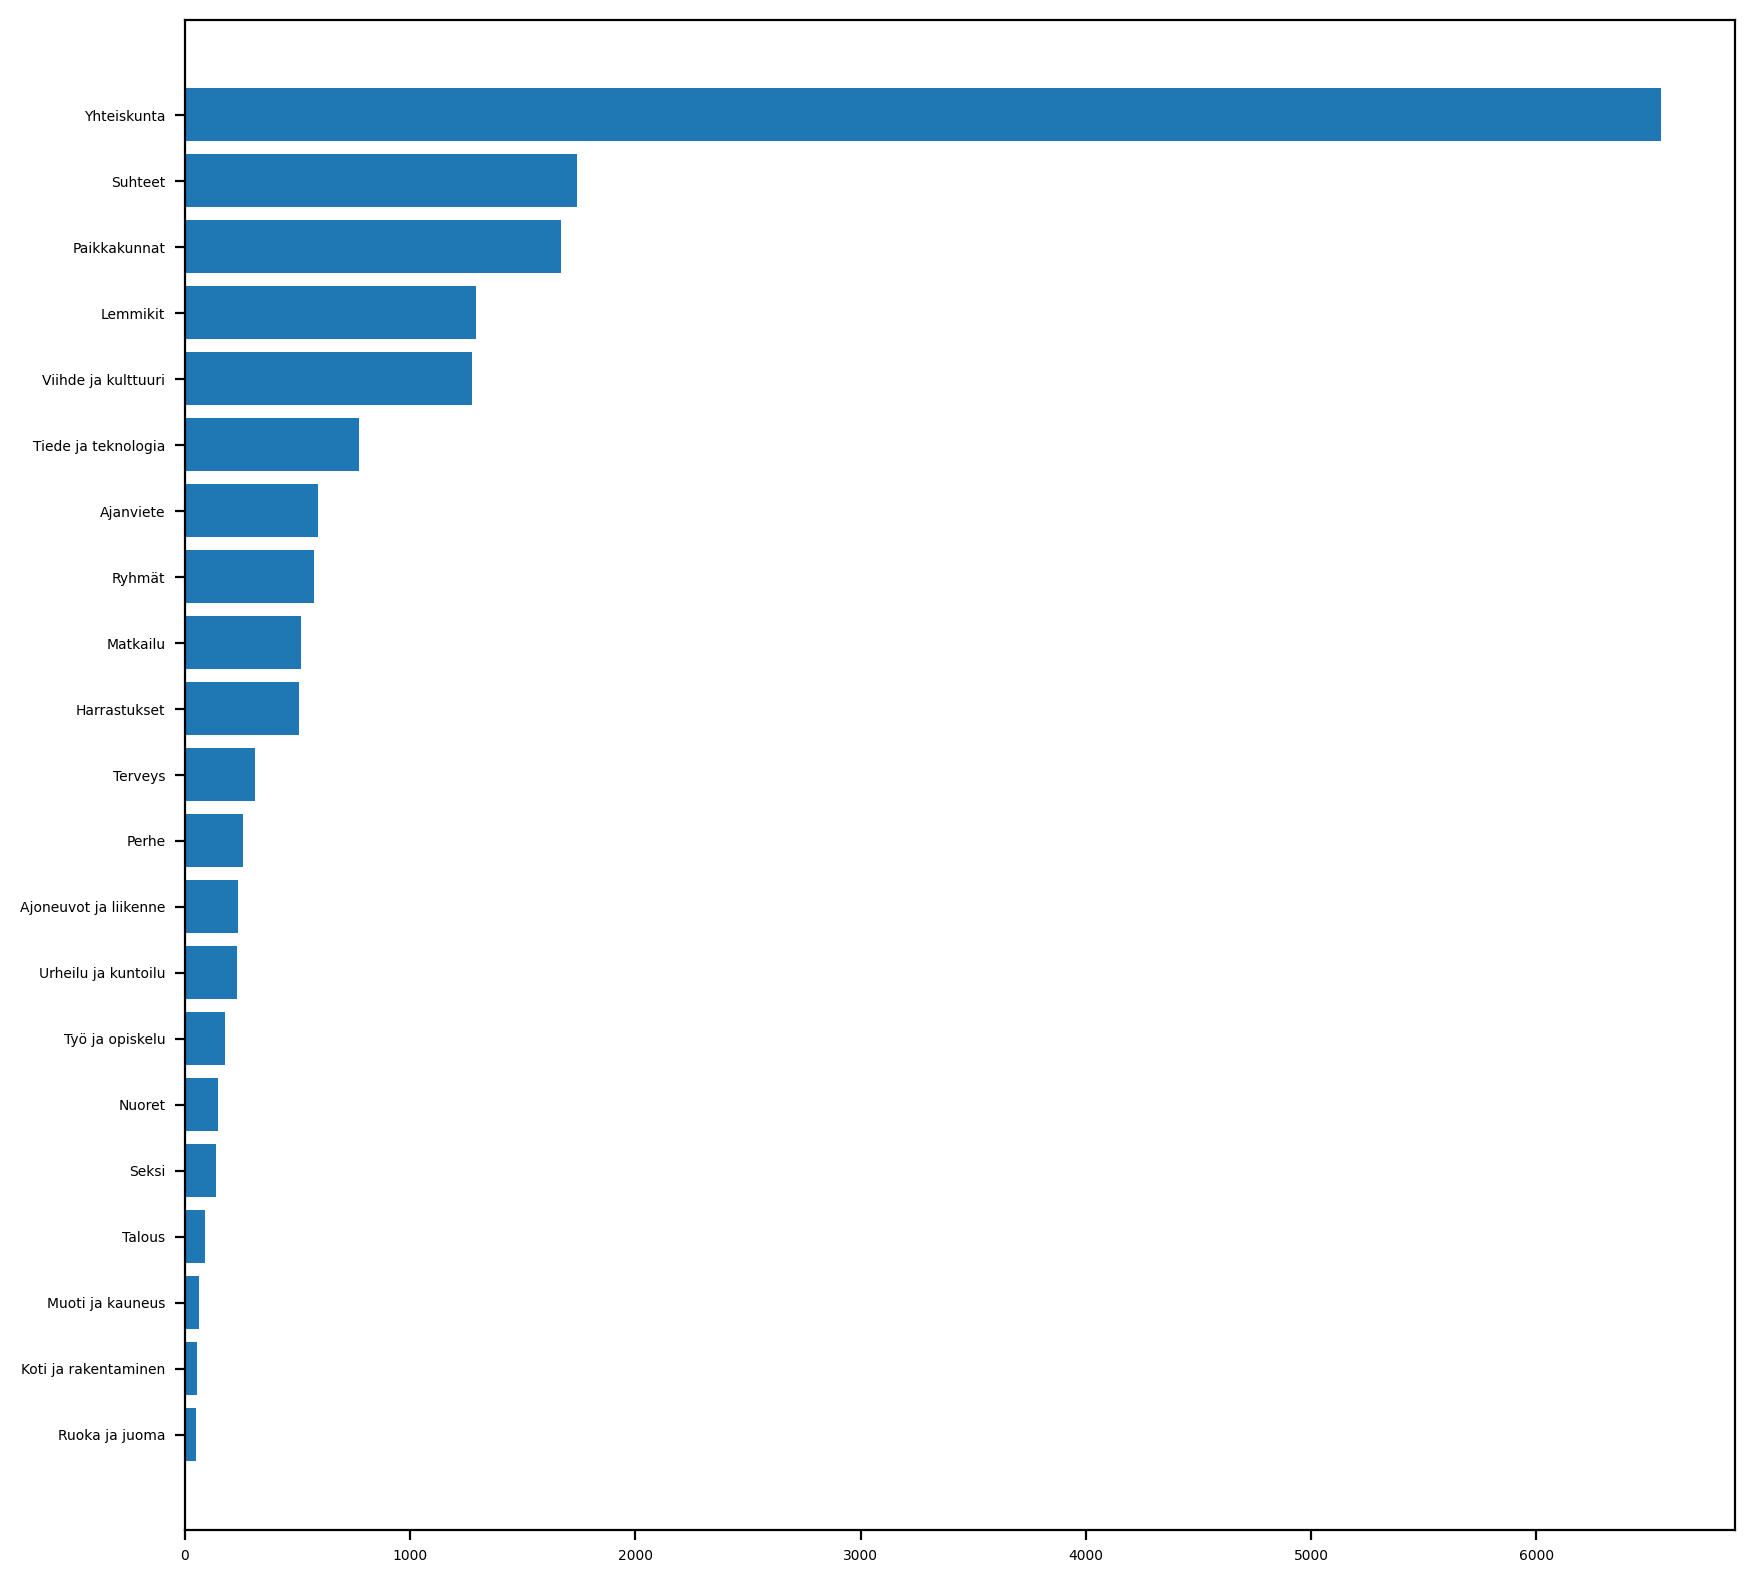

In [ ]:
##what are the main observations?
#now comparing that to "tiikeri" ('tiger) and running the same analyses for it
plt.figure(figsize=(10,10), dpi=200)
plt.rcParams.update({'font.size': 5})
data_B = get_frequency_data_from_korp('[lemma="'+lemmaB+'"]', 'text_topic_name_top', 'suomi24')
data_B = data_B.sort_values('abs_frequency')
plt.barh(data_B['text_topic_name_top'], data_B['abs_frequency'])
plt.show()

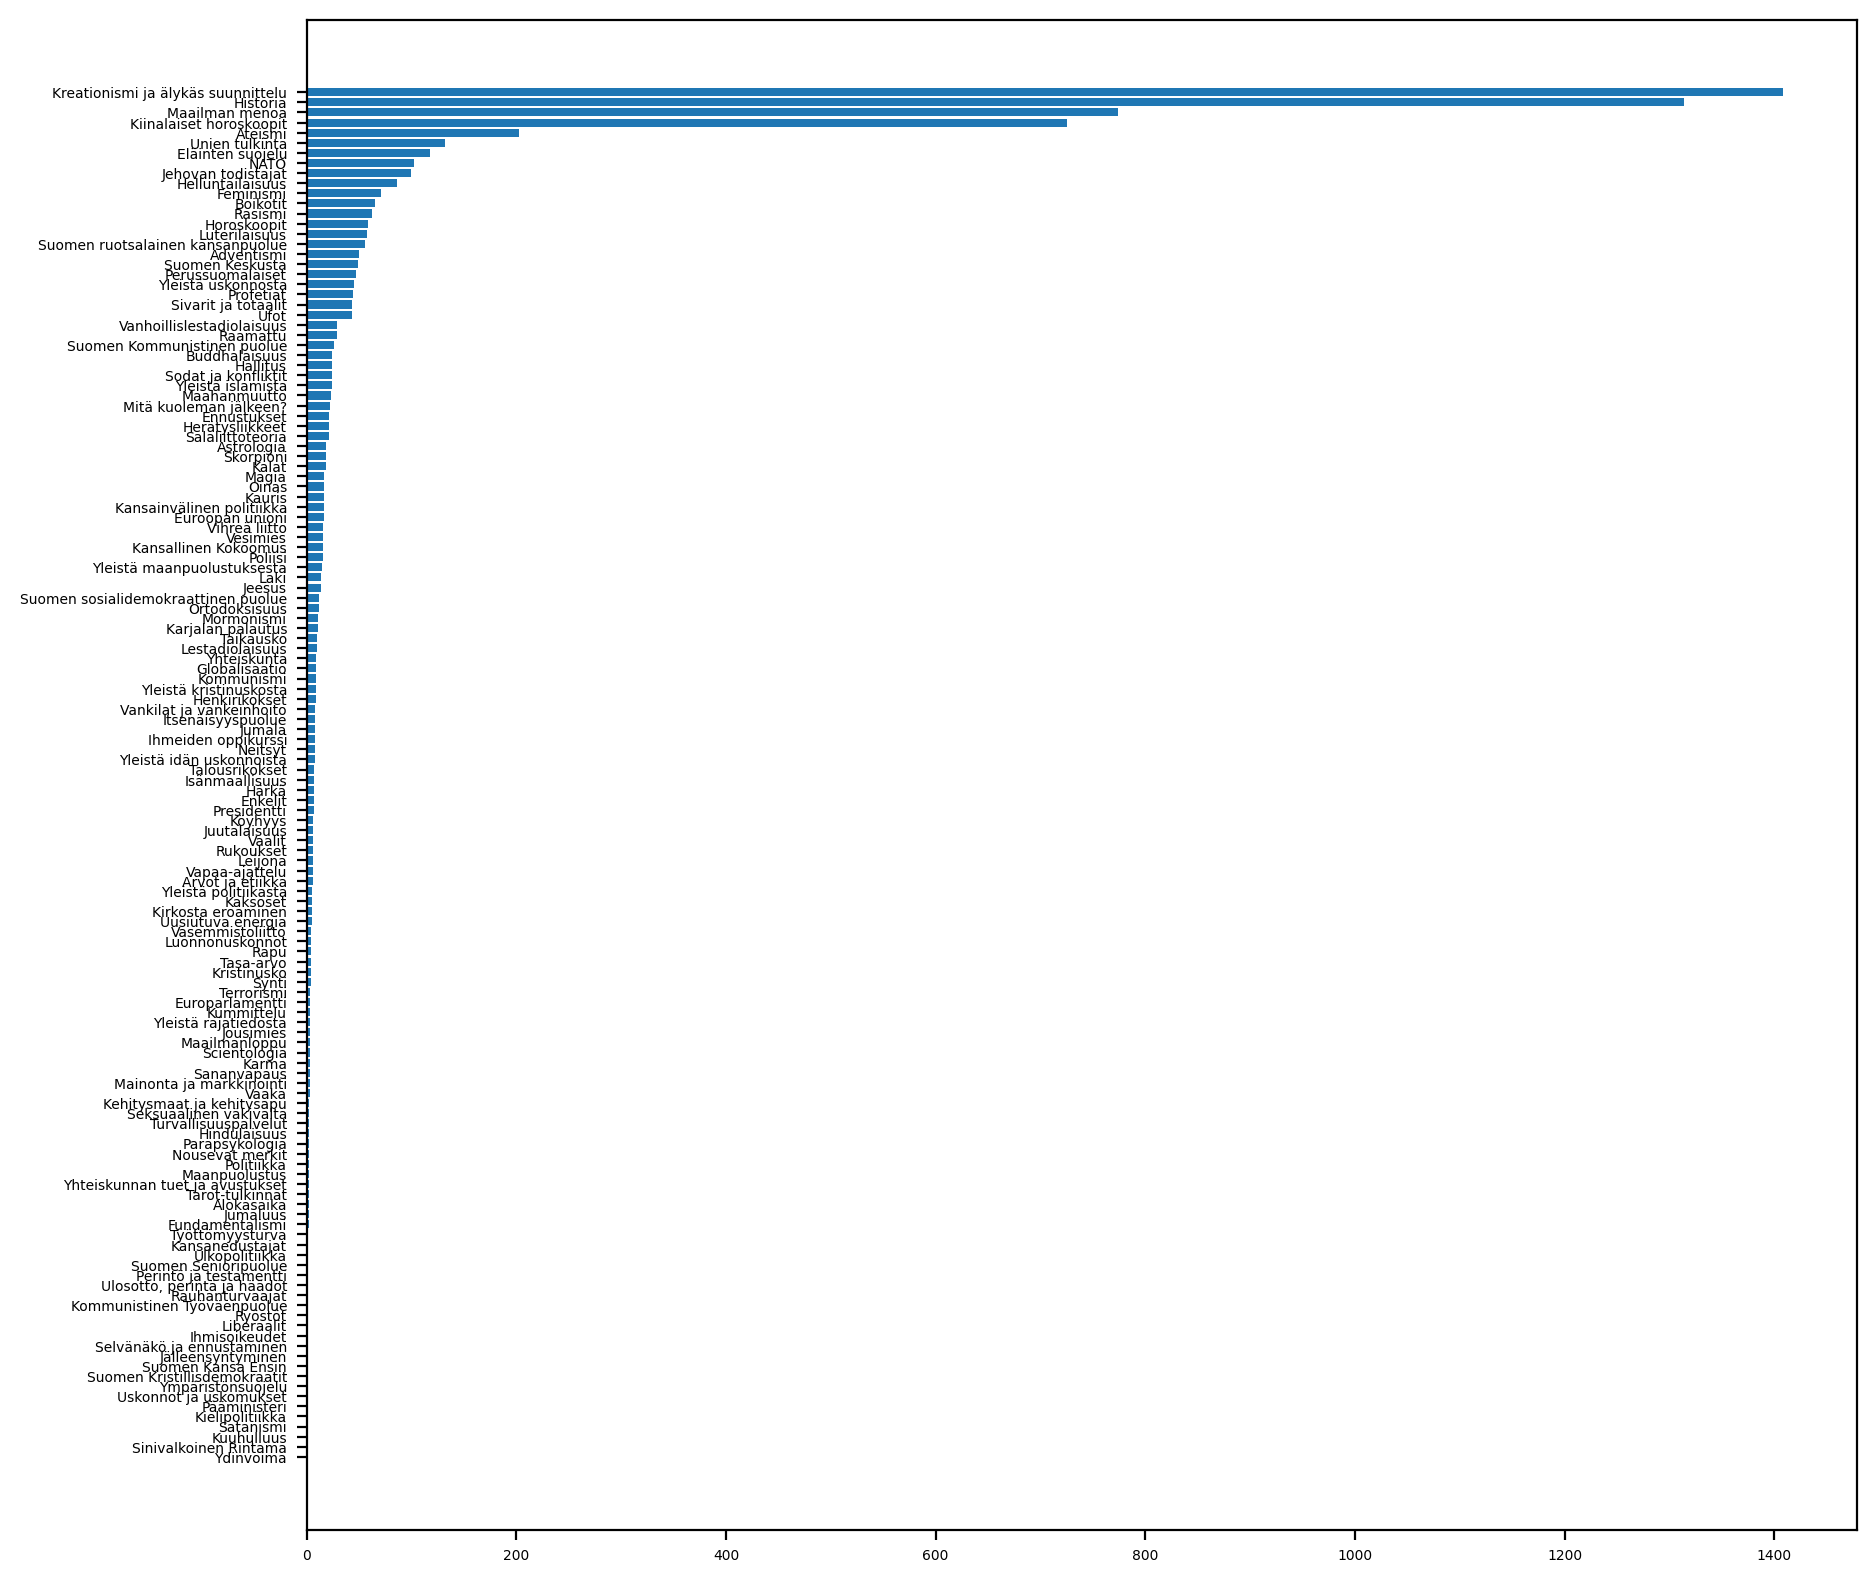

In [ ]:
data_B_soc = get_frequency_data_from_korp('[lemma="'+lemmaB+'" & _.text_topic_name_top = "Yhteiskunta"]', 'text_topic_name_leaf', 'suomi24')
data_B_soc = data_B_soc.sort_values('abs_frequency')
plt.rcParams.update({'font.size': 5})
plt.figure(figsize=(10,10), dpi=200)
plt.barh(data_B_soc['text_topic_name_leaf'], data_B_soc['abs_frequency'])
plt.show()

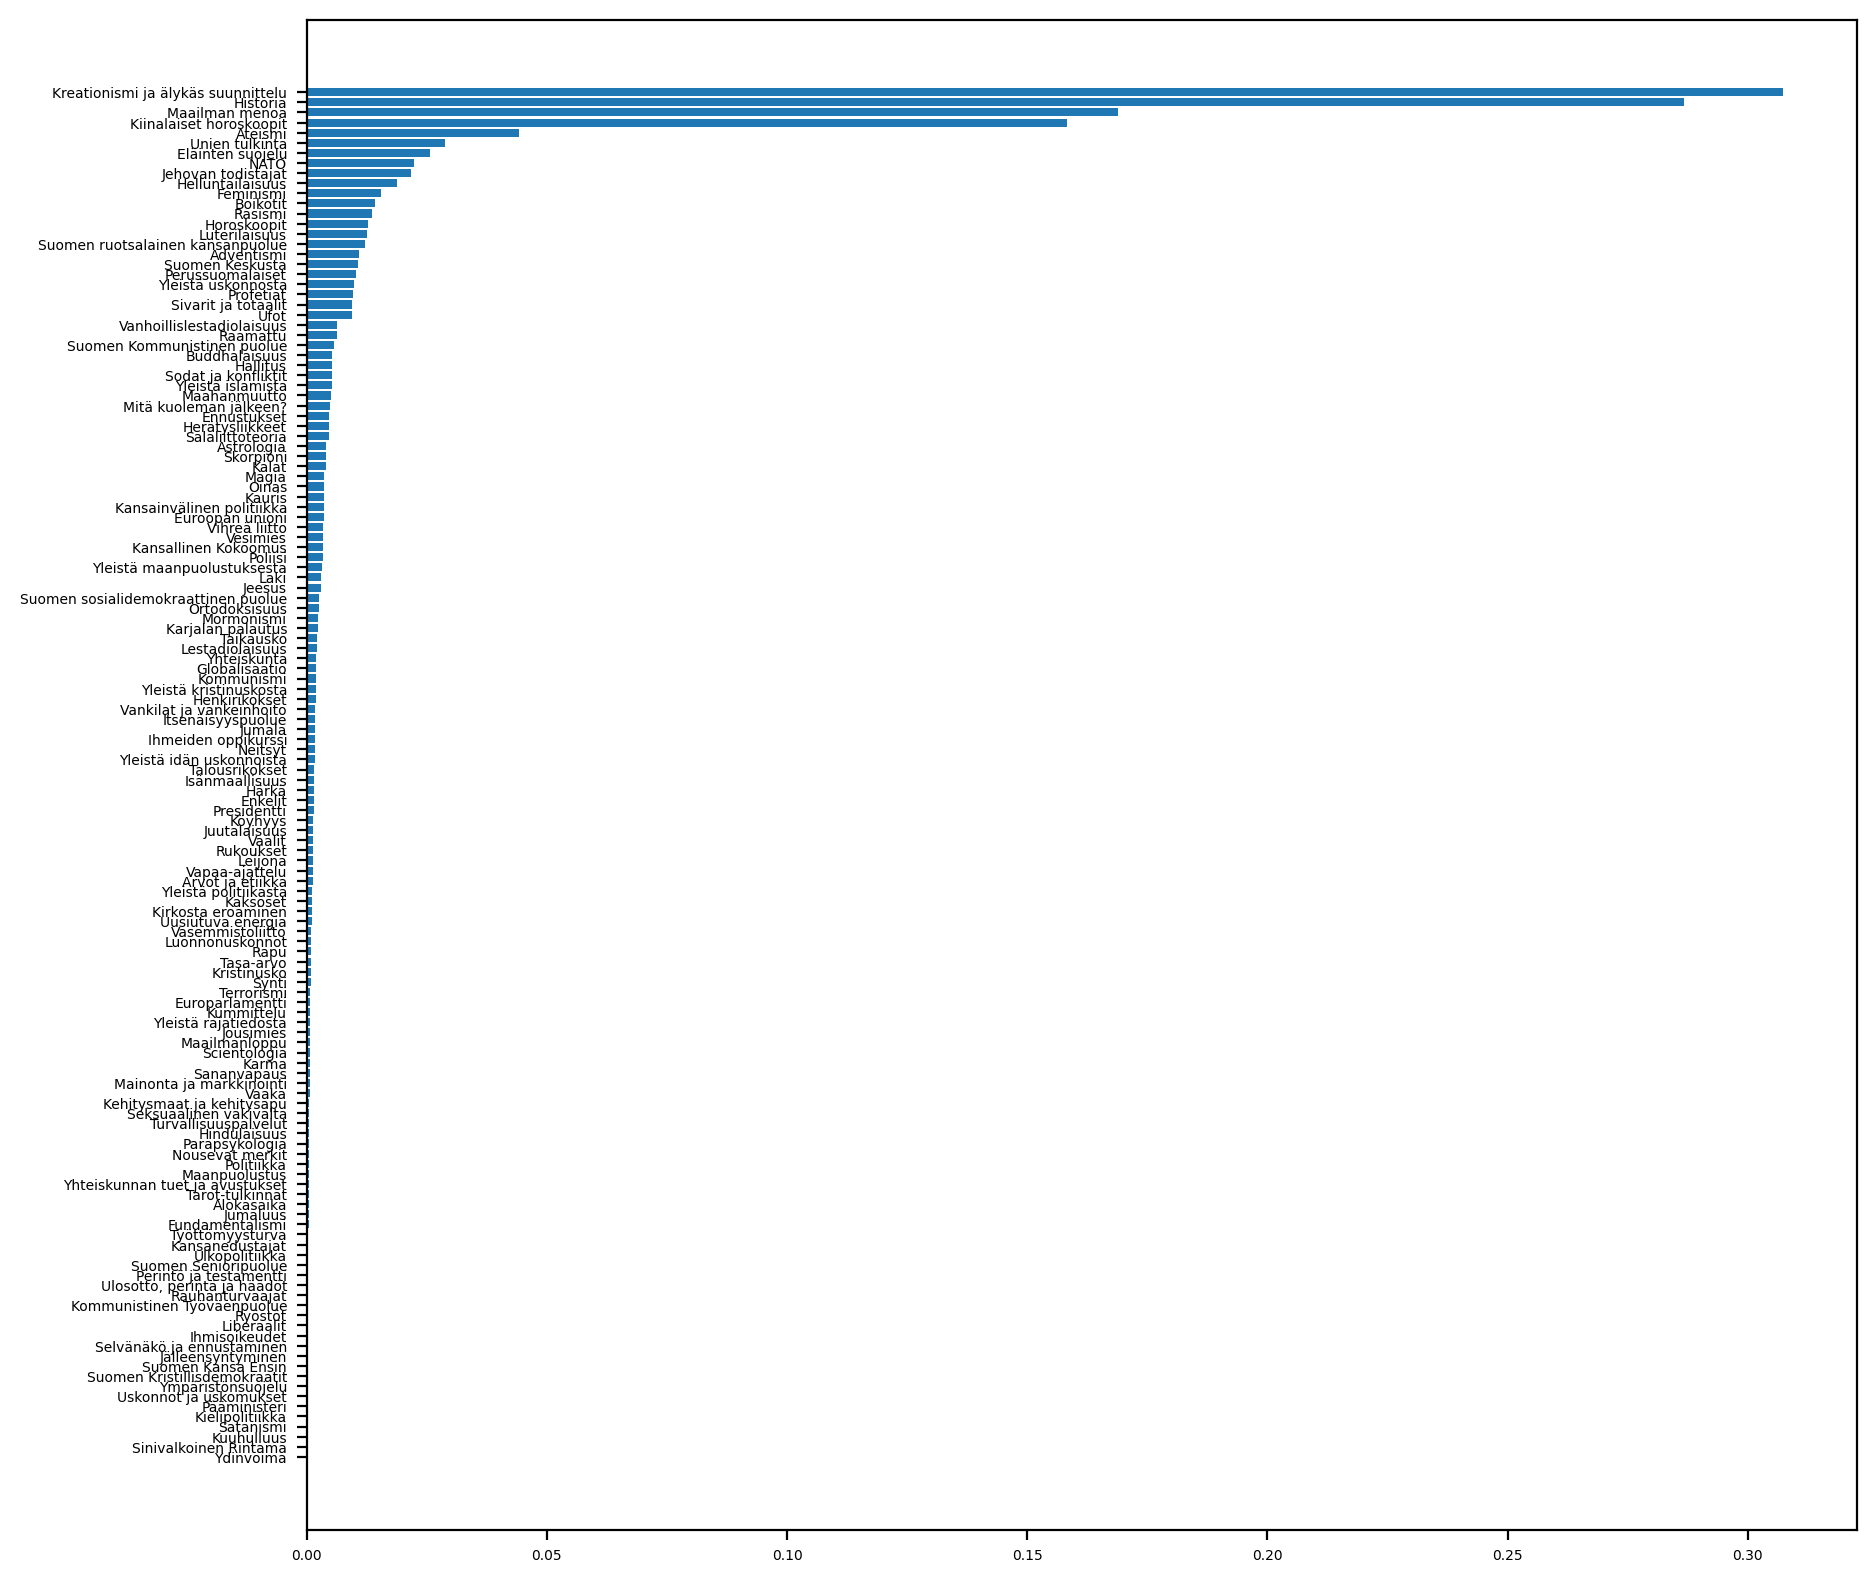

In [ ]:
data_B_soc = get_frequency_data_from_korp('[lemma="'+lemmaB+'" & _.text_topic_name_top = "Yhteiskunta"]', 'text_topic_name_leaf', 'suomi24')
data_B_soc = data_B_soc.sort_values('rel_frequency')
plt.rcParams.update({'font.size': 5})
plt.figure(figsize=(10,10), dpi=200)
plt.barh(data_B_soc['text_topic_name_leaf'], data_B_soc['rel_frequency'])
plt.show()